### ShapeNet: Geometry-Guided Neural Networks for Microscopy Image Analysis


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_25_12112026/shapeNet_data_.ipynb)

## 1. Setup

In [2]:
# %pip install -q pyTEMlib ipympl

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1h2v6YRPG7cwi7kuMPPPdwV0P0PYu49oH?usp=sharing"

In [10]:
from pathlib import Path
import re
import numpy as np
import pyTEMlib.file_tools as ft
import matplotlib.pyplot as plt

def natural_sort_key(path: Path):
    return [
        int(x) if x.isdigit() else x.lower()
        for x in re.split(r"(\d+)", path.name)
    ]


def list_emd_files(folder: Path) -> list[Path]:
    folder = Path(folder)
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder}")
    return sorted(
        [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() == ".emd"],
        key=natural_sort_key,
    )

def load_haadf(file: Path) -> np.ndarray:
    """Load HAADF if available, otherwise Channel_000 or the first 2D dataset."""
    datasets = ft.open_file(str(file))

    if not isinstance(datasets, dict):
        arr = np.squeeze(np.asarray(datasets))
        if arr.ndim != 2:
            raise ValueError(f"No 2D image found in {Path(file).name}")
        return arr

    for key, dset in datasets.items():
        title = str(getattr(dset, "title", ""))
        name = str(getattr(dset, "name", ""))
        if "HAADF" in f"{key} {title} {name}".upper():
            arr = np.squeeze(np.asarray(dset))
            if arr.ndim == 2:
                return arr

    if "Channel_000" in datasets:
        arr = np.squeeze(np.asarray(datasets["Channel_000"]))
        if arr.ndim == 2:
            return arr

    for dset in datasets.values():
        try:
            arr = np.squeeze(np.asarray(dset))
            if arr.ndim == 2:
                return arr
        except Exception:
            pass

    raise ValueError(f"No 2D dataset found in {Path(file).name}")

## 2. Load the images

In [22]:
SISB_DIR = "day_25 data/SiSb/"
YBCO_DIR = "day_25 data/YBCO/"

In [23]:
all_sisb_files = list_emd_files(SISB_DIR)
all_ybco_files = list_emd_files(YBCO_DIR)

N_SISB = 12
sisb_files = all_sisb_files[:N_SISB]
ybco_files = all_ybco_files[:]
sisb_images = [
    load_haadf(file)
    for file in sisb_files
]

ybco_images = [
    load_haadf(file)
    for file in ybco_files
]

(np.float64(-0.5), np.float64(2047.5), np.float64(2047.5), np.float64(-0.5))

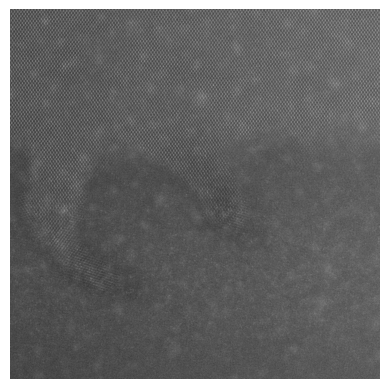

In [24]:
plt.imshow(sisb_images[4], cmap = "grey")
plt.axis("off")

(np.float64(-0.5), np.float64(2047.5), np.float64(2047.5), np.float64(-0.5))

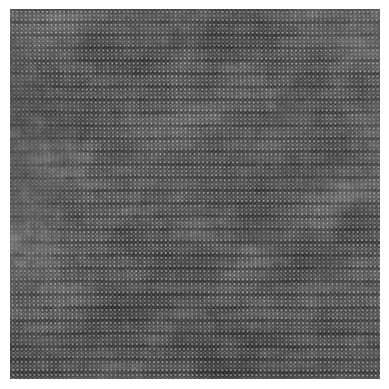

In [25]:
plt.imshow(ybco_images[2], cmap = "grey")
plt.axis("off")

## 3. <font color = "red">**Hackathon Instructions**</font>

In this hackathon, we will explore **lightweight, object-specific neural networks** designed around the geometrical features and shapes of objects in microscopy images.

### Choose one of the following challenges

**<font color = "blue">Challenge 1 — Boundary Detection (SiSb)**</font>

- Identify the boundary separating crystalline and amorphous regions.
- Explore geometric features that distinguish these regions, such as local periodicity, texture, and structural order.
- Develop or propose a lightweight neural network to detect the boundary.
- Visualize the detected boundary overlaid on the original image.

**<font color = "blue">Challenge 2 — Atom Finding (YBCO)**</font>

- Identify atomic columns in the STEM images.
- Explore shape-based features such as atomic-column intensity profiles, symmetry, size, and spatial arrangement.
- Develop or propose a lightweight neural network for atomic-column detection.
- Return the detected atomic coordinates and visualize them on the original image.

### <font color = "green">What you should do</font>

1. **Explore the dataset:** Inspect the images and identify the relevant structural features.
2. **Define the problem:** Determine which geometrical features are most useful for detecting the target objects.
3. **Explore network design:** Consider how these features could be incorporated into a small, object-specific neural network.
4. **Test your approach:** If possible, implement a preliminary method and visualize its predictions.
5. **Discuss your findings:** Explain what works, what does not, and the main limitations of your approach.

You are also encouraged to **use your own experimental images and scientific problems** to explore whether the same approach can be generalized to other materials and imaging modalities.

**The goal is exploratory:** A fully trained or optimized model is not required. Focus on the connection between object geometry, network design, and detection performance.

## Kamyar's approach

Block 1 — Simulate atomic structures

Fe_bcc              : {'Fe': 2}
MgO                 : {'Mg': 4, 'O': 4}
SrTiO3              : {'Sr': 1, 'Ti': 1, 'O': 3}
TiO2_rutile         : {'Ti': 2, 'O': 4}
ZnO_wurtzite        : {'Zn': 2, 'O': 2}
CaCu3Ti4O12         : {'Ca': 2, 'Cu': 6, 'Ti': 8, 'O': 24}


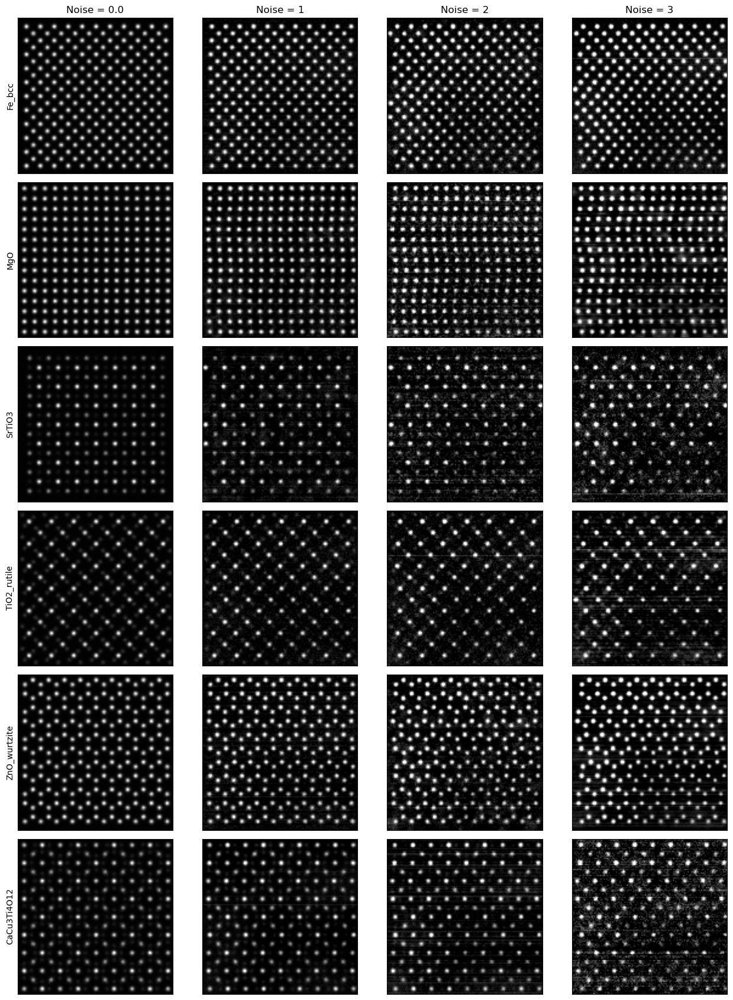

In [54]:

# %% [markdown]
# ## Block 1 — Crystallographic STEM Dataset Simulator
# # Six physically defined crystals with realistic noise

# %%
import numpy as np
import matplotlib.pyplot as plt

from itertools import product
from collections import Counter
from scipy.ndimage import gaussian_filter

# --------------------------------------------------
# 1. Lattice definitions (Angstrom)
# --------------------------------------------------

def cubic(a):
    return np.diag([a, a, a]).astype(float)

def tetragonal(a, c):
    return np.diag([a, a, c]).astype(float)

def hexagonal(a, c):
    return np.array([
        [a, 0, 0],
        [-a/2, np.sqrt(3)*a/2, 0],
        [0, 0, c]
    ], dtype=float)


fcc = np.array([
    [0, 0, 0],
    [0, 0.5, 0.5],
    [0.5, 0, 0.5],
    [0.5, 0.5, 0]
], dtype=float)


# --------------------------------------------------
# 2. Atomic numbers (HAADF contrast approximation)
# --------------------------------------------------

Z = {
    "Fe": 26,
    "Mg": 12,
    "O": 8,
    "Sr": 38,
    "Ti": 22,
    "Ca": 20,
    "Cu": 29,
    "Zn": 30
}


# --------------------------------------------------
# 3. Physically defined crystal structures
# --------------------------------------------------

CRYSTALS = {}

# Fe — BCC
CRYSTALS["Fe_bcc"] = (
    cubic(2.866),
    [
        ("Fe", 0, 0, 0),
        ("Fe", 0.5, 0.5, 0.5)
    ]
)

# MgO — Rocksalt
CRYSTALS["MgO"] = (
    cubic(4.212),
    [("Mg", *p) for p in fcc] +
    [("O", *p) for p in (fcc + [0.5, 0, 0]) % 1]
)

# SrTiO3 — Cubic perovskite
CRYSTALS["SrTiO3"] = (
    cubic(3.905),
    [
        ("Sr", 0, 0, 0),
        ("Ti", 0.5, 0.5, 0.5),
        ("O", 0.5, 0.5, 0),
        ("O", 0.5, 0, 0.5),
        ("O", 0, 0.5, 0.5)
    ]
)

# TiO2 — Rutile
CRYSTALS["TiO2_rutile"] = (
    tetragonal(4.594, 2.959),
    [
        ("Ti", 0, 0, 0),
        ("Ti", 0.5, 0.5, 0.5),
        ("O", 0.305, 0.305, 0),
        ("O", 0.695, 0.695, 0),
        ("O", 0.805, 0.195, 0.5),
        ("O", 0.195, 0.805, 0.5)
    ]
)

# ZnO — Wurtzite
u = 0.382

CRYSTALS["ZnO_wurtzite"] = (
    hexagonal(3.25, 5.207),
    [
        ("Zn", 0, 0, 0),
        ("Zn", 1/3, 2/3, 0.5),
        ("O", 0, 0, u),
        ("O", 1/3, 2/3, (0.5 + u) % 1)
    ]
)

# CaCu3Ti4O12 — Complex cubic perovskite
ca_sites = [
    ("Ca", 0, 0, 0),
    ("Ca", 0.5, 0.5, 0.5)
]

cu_positions = [
    (0.5, 0, 0),
    (0, 0.5, 0),
    (0, 0, 0.5),
    (0, 0.5, 0.5),
    (0.5, 0, 0.5),
    (0.5, 0.5, 0)
]

cu_sites = [("Cu", *p) for p in cu_positions]

ti_sites = [
    ("Ti", *p)
    for p in product([0.25, 0.75], repeat=3)
]

# Oxygen 24g positions
ox, oy = 0.303, 0.179
oxygen_sites = []

for zero_axis in range(3):
    active = [i for i in range(3) if i != zero_axis]

    for sx, sy in product([-1, 1], repeat=2):
        p = np.zeros(3)
        p[active] = [sx * ox, sy * oy]

        for centering in [0, 0.5]:
            q = (p + centering) % 1
            oxygen_sites.append(("O", *q))

CRYSTALS["CaCu3Ti4O12"] = (
    cubic(7.391),
    ca_sites + cu_sites + ti_sites + oxygen_sites
)


# --------------------------------------------------
# 4. Verify crystallographic stoichiometry
# --------------------------------------------------

EXPECTED = {
    "Fe_bcc": {"Fe": 2},
    "MgO": {"Mg": 4, "O": 4},
    "SrTiO3": {"Sr": 1, "Ti": 1, "O": 3},
    "TiO2_rutile": {"Ti": 2, "O": 4},
    "ZnO_wurtzite": {"Zn": 2, "O": 2},
    "CaCu3Ti4O12": {
        "Ca": 2, "Cu": 6, "Ti": 8, "O": 24
    }
}

for name, (cell, sites) in CRYSTALS.items():
    counts = dict(Counter(s[0] for s in sites))
    assert counts == EXPECTED[name], name
    print(f"{name:20s}: {counts}")


# --------------------------------------------------
# 5. Generate projected atomic columns
# --------------------------------------------------

def project_crystal(
    structure,
    zone_axis,
    size,
    pixel_size,
    thickness
):

    cell, sites = CRYSTALS[structure]
    fov = size * pixel_size

    # Beam direction in Cartesian coordinates
    ez = np.asarray(zone_axis, dtype=float) @ cell
    ez /= np.linalg.norm(ez)

    ref = (
        np.array([0., 1., 0.])
        if abs(ez[2]) > 0.9
        else np.array([0., 0., 1.])
    )

    ex = np.cross(ref, ez)
    ex /= np.linalg.norm(ex)
    ey = np.cross(ez, ex)

    # Periodic supercell large enough for projection
    radius = np.sqrt(
        (fov / np.sqrt(2))**2 +
        (thickness / 2)**2
    )

    radius += max(np.linalg.norm(cell, axis=1))

    n = np.ceil(
        radius * np.linalg.norm(
            np.linalg.inv(cell), axis=0
        )
    ).astype(int) + 1

    grid = np.meshgrid(
        *(np.arange(-ni, ni+1) for ni in n),
        indexing="ij"
    )

    shifts = np.column_stack(
        [g.ravel() for g in grid]
    )

    xy_list = []
    mass_list = []

    for element, x, y, z in sites:

        xyz = (
            shifts + np.array([x, y, z])
        ) @ cell

        px = xyz @ ex / pixel_size + size / 2
        py = xyz @ ey / pixel_size + size / 2
        pz = xyz @ ez

        keep = (
            (np.abs(pz) <= thickness / 2) &
            (px >= -5) & (px < size+5) &
            (py >= -5) & (py < size+5)
        )

        xy_list.append(
            np.column_stack([px[keep], py[keep]])
        )

        mass_list.append(
            np.full(
                keep.sum(),
                Z[element]**1.7
            )
        )

    xy = np.concatenate(xy_list)
    mass = np.concatenate(mass_list)

    # Merge projected atomic sites into columns
    coords, inverse = np.unique(
        np.round(xy, 3),
        axis=0,
        return_inverse=True
    )

    weights = np.bincount(
        inverse,
        weights=mass
    )

    return coords, weights


# --------------------------------------------------
# 6. Scan distortion — transform atomic coordinates
# --------------------------------------------------

def distort_coordinates(coords, size, rng, strength=1.0):
    """
    Simulate raster scan distortion.

    Applies the distortion directly to atomic
    coordinates before rendering the image.

    Therefore, image and labels remain aligned.
    """

    coords = coords.copy()

    x = coords[:, 0]
    y = coords[:, 1]

    # Slow drift / shear
    drift_x = rng.uniform(-1.0, 1.0) * strength
    drift_y = rng.uniform(-0.5, 0.5) * strength

    x_new = x + drift_x * (y / size)
    y_new = y + drift_y * (x / size)

    # Scan-line displacement
    amplitude = rng.uniform(0, 0.8) * strength
    period = rng.uniform(20, 80)
    phase = rng.uniform(0, 2*np.pi)

    x_new += amplitude * np.sin(
        2*np.pi*y / period + phase
    )

    return np.column_stack([x_new, y_new])


# --------------------------------------------------
# 7. Render atomic-column image and ground truth
# --------------------------------------------------

def render_columns(
    coords,
    weights,
    size,
    sigma
):

    image = np.zeros((size, size), dtype=np.float32)
    heatmap = np.zeros_like(image)

    # Fixed target peak width independent of probe size
    target_sigma = 1.0

    for (x, y), w in zip(coords, weights):

        radius = int(np.ceil(
            4 * max(sigma, target_sigma)
        ))

        x0 = max(0, int(np.floor(x)) - radius)
        x1 = min(size, int(np.ceil(x)) + radius + 1)

        y0 = max(0, int(np.floor(y)) - radius)
        y1 = min(size, int(np.ceil(y)) + radius + 1)

        if x0 >= x1 or y0 >= y1:
            continue

        yy, xx = np.mgrid[y0:y1, x0:x1]

        r2 = (xx-x)**2 + (yy-y)**2

        image[y0:y1, x0:x1] += (
            w * np.exp(-r2 / (2*sigma**2))
        )

        heatmap[y0:y1, x0:x1] = np.maximum(
            heatmap[y0:y1, x0:x1],
            np.exp(-r2 / (2*target_sigma**2))
        )

    image /= image.max() + 1e-8

    return image, heatmap


# --------------------------------------------------
# 8. Realistic STEM noise and imaging artifacts
# --------------------------------------------------

def add_stem_noise(
    image,
    rng,
    dose=800,
    background=0.01,
    noise_strength=2.0
):
    """
    Approximate experimental STEM acquisition effects.

    Includes:
    - Poisson shot noise
    - Gaussian detector noise
    - Spatially correlated noise
    - Scan-line noise
    - Low-frequency background variation
    """

    H, W = image.shape

    # Low-frequency background
    background_map = rng.normal(
        0, 1, (H, W)
    )

    background_map = gaussian_filter(
        background_map, sigma=15
    )

    background_map /= (
        background_map.std() + 1e-8
    )

    background_map *= (
        rng.uniform(0, 0.025) * noise_strength
    )

    # Smooth multiplicative contrast variation
    contrast_map = gaussian_filter(
        rng.normal(0, 1, (H, W)),
        sigma=20
    )

    contrast_map /= (
        contrast_map.std() + 1e-8
    )

    contrast_map = 1 + (
        rng.uniform(0, 0.15) *
        noise_strength *
        contrast_map
    )

    signal = image * np.clip(
        contrast_map, 0.3, 2.0
    )

    signal += background + background_map
    signal = np.clip(signal, 0, None)

    # Poisson shot noise
    # dose is an effective count scale, not
    # a calibrated experimental electron dose.
    counts = rng.poisson(
        signal * dose
    )

    noisy = counts / dose

    # Gaussian detector noise
    read_noise = rng.uniform(
        0.005, 0.04
    ) * noise_strength

    noisy += rng.normal(
        0, read_noise, (H, W)
    )

    # Spatially correlated noise
    correlated = gaussian_filter(
        rng.normal(0, 1, (H, W)),
        sigma=rng.uniform(0.5, 2.0)
    )

    correlated /= (
        correlated.std() + 1e-8
    )

    noisy += (
        correlated *
        rng.uniform(0, 0.035) *
        noise_strength
    )

    # Horizontal scan-line intensity fluctuations
    line_noise = rng.normal(
        0,
        rng.uniform(0, 0.025) * noise_strength,
        size=(H, 1)
    )

    noisy += line_noise

    # Occasional scan-line artifacts
    if rng.random() < 0.5 * min(noise_strength, 1):
        n_lines = int(rng.integers(1, 5))
        rows = rng.choice(H, size=n_lines, replace=False)

        for row in rows:
            noisy[row] += rng.uniform(-0.08, 0.08) * noise_strength

    # Preserve a consistent intensity range
    noisy = np.clip(noisy, 0, 1)

    return noisy.astype(np.float32)


# --------------------------------------------------
# 9. Complete STEM simulator
# --------------------------------------------------

def simulate_atoms(
    structure,
    zone_axis=(0, 0, 1),
    size=128,
    pixel_size=0.25,
    thickness=30.0,
    sigma=1.0,
    dose=800,
    background=0.01,
    noise_strength=2.0,
    seed=None
):

    rng = np.random.default_rng(seed)

    # Project physically defined crystal
    coords, weights = project_crystal(
        structure,
        zone_axis,
        size,
        pixel_size,
        thickness
    )

    # Scan distortion with coordinate alignment
    coords = distort_coordinates(
        coords,
        size,
        rng,
        strength=noise_strength
    )

    # Keep atomic columns inside image
    valid = (
        (coords[:, 0] >= 2) &
        (coords[:, 0] < size-2) &
        (coords[:, 1] >= 2) &
        (coords[:, 1] < size-2)
    )

    coords = coords[valid]
    weights = weights[valid]

    # Render projected HAADF intensity
    image, heatmap = render_columns(
        coords,
        weights,
        size,
        sigma
    )

    # Add acquisition noise
    image = add_stem_noise(
        image,
        rng,
        dose=dose,
        background=background,
        noise_strength=noise_strength
    )

    return (
        image.astype(np.float32),
        heatmap.astype(np.float32),
        coords.astype(np.float32)
    )


# --------------------------------------------------
# 10. Visualize different noise levels
# --------------------------------------------------

zone_axes = {
    "SrTiO3": (0, 0, 1),
    "CaCu3Ti4O12": (0, 0, 1),
    "ZnO_wurtzite": (0, 0, 1),
    "Fe_bcc": (0, 0, 1),
    "TiO2_rutile": (0, 0, 1),
    "MgO": (0, 0, 1)
}

noise_levels = [0.0, 1, 2, 3]

fig, axes = plt.subplots(
    len(CRYSTALS),
    len(noise_levels),
    figsize=(13, 17)
)

for i, structure in enumerate(CRYSTALS):

    for j, noise in enumerate(noise_levels):

        image, heatmap, coords = simulate_atoms(
            structure=structure,
            zone_axis=zone_axes[structure],
            size=128,
            pixel_size=0.25,
            thickness=30,
            sigma=1.2,
            dose=500,
            noise_strength=noise,
            seed=42
        )

        ax = axes[i, j]
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)

        if i == 0:
            ax.set_title(f"Noise = {noise}")

        if j == 0:
            ax.set_ylabel(structure, fontsize=10)

        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


## Block 2 — Generate ShapeNet Training Dataset

train: 756 images saved
val: 162 images saved
test: 162 images saved


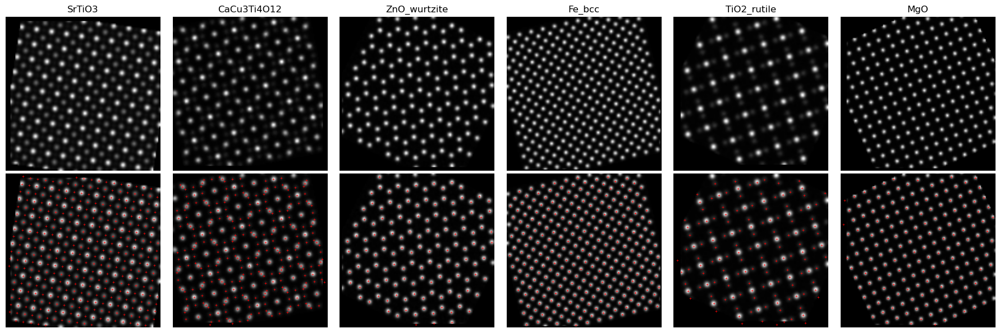

In [ ]:

# %% [markdown]
# ## Block 2 — Generate ShapeNet Training Dataset

# %%
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import rotate, shift

# --------------------------------------------------
# 1. Dataset configuration
# --------------------------------------------------

OUTPUT_DIR = Path("shapenet_dataset").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ZONE_AXES = {
    "SrTiO3":        [(0,0,1), (1,1,0), (1,1,1)],
    "CaCu3Ti4O12":   [(0,0,1), (1,1,0), (1,1,1)],
    "ZnO_wurtzite":  [(0,0,1), (1,0,0), (1,1,0)],
    "Fe_bcc":        [(0,0,1), (1,1,0), (1,1,1)],
    "TiO2_rutile":   [(0,0,1), (1,1,0), (1,0,0)],
    "MgO":           [(0,0,1), (1,1,0), (1,1,1)]
}

assert set(ZONE_AXES) == set(CRYSTALS)

rng = np.random.default_rng(42)

# Samples per structure per zone axis
SPLITS = {
    "train": 42,
    "val": 9,
    "test": 9
}

# --------------------------------------------------
# 2. Geometric augmentation
# --------------------------------------------------

def augment_sample(image, heatmap, coords, angle, dx, dy):
    """
    Rotate and translate the image, heatmap,
    and atomic coordinates consistently.
    """

    size = image.shape[0]
    center = (size - 1) / 2

    image = rotate(
        image,
        angle,
        reshape=False,
        order=1,
        mode="constant",
        cval=0
    )

    # Transform coordinates before rebuilding target heatmap
    theta = np.deg2rad(angle)

    x = coords[:, 0] - center
    y = coords[:, 1] - center

    new_x = (
        center +
        x * np.cos(theta) +
        y * np.sin(theta) +
        dx
    )

    new_y = (
        center -
        x * np.sin(theta) +
        y * np.cos(theta) +
        dy
    )

    coords = np.column_stack([new_x, new_y])

    image = shift(
        image,
        shift=(dy, dx),
        order=1,
        mode="constant",
        cval=0
    )

    # Keep centers inside the image
    valid = (
        (coords[:, 0] >= 2) &
        (coords[:, 0] < size-2) &
        (coords[:, 1] >= 2) &
        (coords[:, 1] < size-2)
    )

    coords = coords[valid].astype(np.float32)

    # Rebuild ground-truth heatmap from transformed coordinates
    # to avoid interpolation-induced target shifts.
    heatmap = np.zeros((size, size), dtype=np.float32)

    target_sigma = 1.0
    radius = 4

    for x, y in coords:
        x0 = max(0, int(np.floor(x)) - radius)
        x1 = min(size, int(np.ceil(x)) + radius + 1)
        y0 = max(0, int(np.floor(y)) - radius)
        y1 = min(size, int(np.ceil(y)) + radius + 1)

        yy, xx = np.mgrid[y0:y1, x0:x1]

        spot = np.exp(
            -((xx-x)**2 + (yy-y)**2) /
            (2 * target_sigma**2)
        )

        heatmap[y0:y1, x0:x1] = np.maximum(
            heatmap[y0:y1, x0:x1],
            spot
        )

    return (
        image.astype(np.float32),
        heatmap,
        coords
    )


# --------------------------------------------------
# 3. Generate train / validation / test datasets
# --------------------------------------------------

for split, n_samples in SPLITS.items():

    images = []
    heatmaps = []
    all_coords = []
    offsets = [0]

    structures = []
    zone_labels = []
    parameters = []

    for structure, axes in ZONE_AXES.items():

        for zone in axes:

            for _ in range(n_samples):

                # Imaging parameters
                pixel_size = rng.uniform(0.18, 0.35)
                thickness = rng.uniform(20, 50)
                sigma = rng.uniform(0.8, 1.5)
                dose = rng.uniform(150, 1200)

                # Noise conditions
                noise_strength = rng.uniform(0.0, 1.5)
                background = rng.uniform(0.0, 0.04)

                seed = int(
                    rng.integers(0, 2**31 - 1)
                )

                # Physically defined crystal + noisy STEM simulation
                image, heatmap, coords = simulate_atoms(
                    structure=structure,
                    zone_axis=zone,
                    size=128,
                    pixel_size=pixel_size,
                    thickness=thickness,
                    sigma=sigma,
                    dose=dose,
                    background=background,
                    noise_strength=noise_strength,
                    seed=seed
                )

                # Random rotation and translation
                angle = rng.uniform(0, 360)
                dx, dy = rng.uniform(-6, 6, size=2)

                image, heatmap, coords = augment_sample(
                    image,
                    heatmap,
                    coords,
                    angle,
                    dx,
                    dy
                )

                images.append(image)
                heatmaps.append(heatmap)

                all_coords.append(coords)
                offsets.append(
                    offsets[-1] + len(coords)
                )

                structures.append(structure)
                zone_labels.append(zone)

                parameters.append([
                    pixel_size,
                    thickness,
                    sigma,
                    dose,
                    noise_strength,
                    background,
                    angle,
                    dx,
                    dy
                ])

    # --------------------------------------------------
    # 4. Save dataset without ZIP compression
    # --------------------------------------------------

    file_path = OUTPUT_DIR / f"{split}.npz"

    np.savez(
        file_path,
        images=np.stack(images).astype(np.float32),
        heatmaps=np.stack(heatmaps).astype(np.float32),
        coords=np.concatenate(all_coords).astype(np.float32),
        offsets=np.asarray(offsets, dtype=np.int64),
        structures=np.asarray(structures),
        zone_axes=np.asarray(zone_labels),
        parameters=np.asarray(parameters, dtype=np.float32)
    )

    print(
        f"{split:5s}: {len(images)} images | "
        f"{file_path.stat().st_size / 1e6:.1f} MB"
    )


# --------------------------------------------------
# 5. Visualize training samples
# --------------------------------------------------

with np.load(OUTPUT_DIR / "train.npz") as data:

    images = data["images"]
    heatmaps = data["heatmaps"]
    all_coords = data["coords"]
    offsets = data["offsets"]
    labels = data["structures"]

fig, axes = plt.subplots(
    3, 6,
    figsize=(18, 9)
)

for j, structure in enumerate(ZONE_AXES):

    indices = np.where(labels == structure)[0]

    # Pick a representative noisy image
    i = indices[len(indices) // 2]

    image = images[i]
    heatmap = heatmaps[i]

    coords = all_coords[
        offsets[i]:offsets[i+1]
    ]

    # Simulated noisy STEM
    axes[0, j].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(structure)

    # Ground-truth heatmap
    axes[1, j].imshow(
        heatmap,
        cmap="inferno",
        vmin=0,
        vmax=1
    )

    # Atomic coordinates
    axes[2, j].imshow(image, cmap="gray", vmin=0, vmax=1)

    axes[2, j].scatter(
        coords[:, 0],
        coords[:, 1],
        s=8,
        facecolors="none",
        edgecolors="red",
        linewidths=0.6
    )

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].set_ylabel("Noisy STEM")
axes[1, 0].set_ylabel("Ground Truth")
axes[2, 0].set_ylabel("Atom Coordinates")

plt.tight_layout()
plt.show()



## Block 3 — Define the geometry-aware neural network

train | SrTiO3               completed
train | CaCu3Ti4O12          completed
train | ZnO_wurtzite         completed
train | Fe_bcc               completed
train | TiO2_rutile          completed
train | MgO                  completed

TRAIN COMPLETE
Full images: 756
Training patches: 1764
Saved: /Users/kbarakat/shapenet_dataset_multires/train.npz

val   | SrTiO3               completed
val   | CaCu3Ti4O12          completed
val   | ZnO_wurtzite         completed
val   | Fe_bcc               completed
val   | TiO2_rutile          completed
val   | MgO                  completed

VAL COMPLETE
Full images: 162
Training patches: 378
Saved: /Users/kbarakat/shapenet_dataset_multires/val.npz

test  | SrTiO3               completed
test  | CaCu3Ti4O12          completed
test  | ZnO_wurtzite         completed
test  | Fe_bcc               completed
test  | TiO2_rutile          completed
test  | MgO                  completed

TEST COMPLETE
Full images: 162
Training patches: 378
Saved: /Users/kba

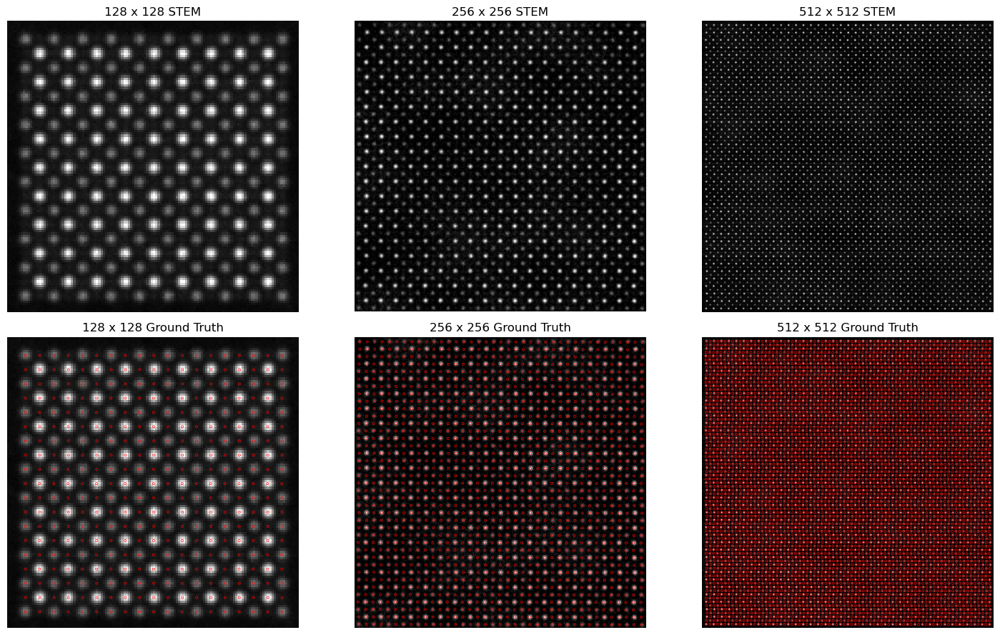

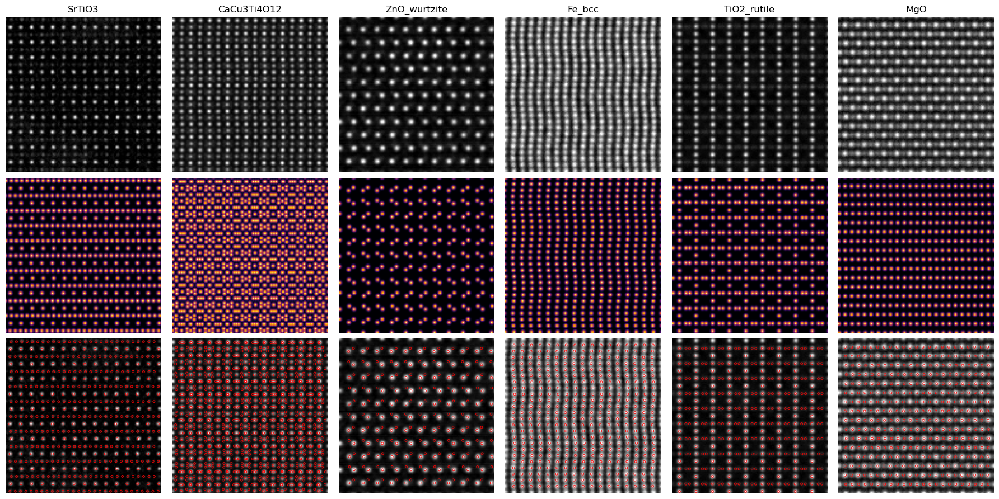

In [58]:

# %% [markdown]
# ## Block 2 — Multiresolution ShapeNet Dataset
# # Full images: 128, 256, 512
# # Training patches: 128 x 128

# %%
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# --------------------------------------------------
# 1. Dataset configuration
# --------------------------------------------------

# Save locally to avoid OneDrive write timeouts
OUTPUT_DIR = Path.home() / "shapenet_dataset_multires"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZES = [128, 256, 512]
PATCH_SIZE = 128

# Patches extracted from each full image
PATCHES_PER_IMAGE = {
    128: 1,
    256: 2,
    512: 4
}

ZONE_AXES = {
    "SrTiO3": [
        (0,0,1), (1,1,0), (1,1,1)
    ],
    "CaCu3Ti4O12": [
        (0,0,1), (1,1,0), (1,1,1)
    ],
    "ZnO_wurtzite": [
        (0,0,1), (1,0,0), (1,1,0)
    ],
    "Fe_bcc": [
        (0,0,1), (1,1,0), (1,1,1)
    ],
    "TiO2_rutile": [
        (0,0,1), (1,1,0), (1,0,0)
    ],
    "MgO": [
        (0,0,1), (1,1,0), (1,1,1)
    ]
}

assert set(ZONE_AXES) == set(CRYSTALS)

# Samples per structure, zone axis, and image size
SPLITS = {
    "train": 14,
    "val": 3,
    "test": 3
}

rng = np.random.default_rng(42)


# --------------------------------------------------
# 2. Extract 128 x 128 training patches
# --------------------------------------------------

def extract_patches(
    image,
    heatmap,
    coords,
    patch_size=128,
    n_patches=4,
    rng=None
):
    """
    Extract random patches from a simulated image.

    Atomic coordinates are transformed into local
    patch coordinates.

    Image and ground truth remain aligned.
    """

    if rng is None:
        rng = np.random.default_rng()

    H, W = image.shape

    if H < patch_size or W < patch_size:
        raise ValueError("Image smaller than patch size")

    patches = []

    for _ in range(n_patches):

        x0 = int(rng.integers(0, W - patch_size + 1))
        y0 = int(rng.integers(0, H - patch_size + 1))

        # Image and target crop
        patch = image[
            y0:y0+patch_size,
            x0:x0+patch_size
        ].copy()

        target = heatmap[
            y0:y0+patch_size,
            x0:x0+patch_size
        ].copy()

        # Convert global coordinates to patch coordinates
        local_coords = coords.copy()

        local_coords[:, 0] -= x0
        local_coords[:, 1] -= y0

        valid = (
            (local_coords[:, 0] >= 2) &
            (local_coords[:, 0] < patch_size-2) &
            (local_coords[:, 1] >= 2) &
            (local_coords[:, 1] < patch_size-2)
        )

        local_coords = local_coords[valid]

        patches.append((
            patch.astype(np.float32),
            target.astype(np.float32),
            local_coords.astype(np.float32)
        ))

    return patches


# --------------------------------------------------
# 3. Generate multiresolution data
# --------------------------------------------------

for split, n_samples in SPLITS.items():

    full_dir = OUTPUT_DIR / "full_images" / split
    full_dir.mkdir(parents=True, exist_ok=True)

    images = []
    heatmaps = []
    all_coords = []

    offsets = [0]
    structures = []
    zone_labels = []
    source_sizes = []
    parameters = []

    full_count = 0

    for structure, axes in ZONE_AXES.items():

        for zone in axes:

            for size in IMAGE_SIZES:

                for sample_id in range(n_samples):

                    # --------------------------
                    # Imaging parameters
                    # --------------------------

                    pixel_size = rng.uniform(0.18, 0.35)
                    thickness = rng.uniform(20, 50)

                    sigma = rng.uniform(0.8, 1.8)
                    dose = rng.uniform(100, 1500)

                    # --------------------------
                    # Noise parameters
                    # --------------------------

                    noise_strength = rng.uniform(0.0, 1.5)
                    background = rng.uniform(0.0, 0.04)

                    seed = int(
                        rng.integers(0, 2**31 - 1)
                    )

                    # --------------------------
                    # Simulate STEM image
                    # --------------------------

                    image, heatmap, coords = simulate_atoms(
                        structure=structure,
                        zone_axis=zone,
                        size=size,
                        pixel_size=pixel_size,
                        thickness=thickness,
                        sigma=sigma,
                        dose=dose,
                        background=background,
                        noise_strength=noise_strength,
                        seed=seed
                    )

                    # --------------------------
                    # Save full-resolution image
                    # --------------------------

                    zone_name = "".join(map(str, zone))

                    filename = (
                        f"{structure}_"
                        f"{zone_name}_"
                        f"{size}_"
                        f"{sample_id:03d}.npz"
                    )

                    np.savez(
                        full_dir / filename,
                        image=image.astype(np.float32),
                        heatmap=heatmap.astype(np.float32),
                        coords=coords.astype(np.float32),
                        structure=np.array(structure),
                        zone_axis=np.asarray(zone),
                        pixel_size=np.float32(pixel_size),
                        thickness=np.float32(thickness),
                        sigma=np.float32(sigma),
                        dose=np.float32(dose),
                        noise_strength=np.float32(noise_strength),
                        background=np.float32(background)
                    )

                    full_count += 1

                    # --------------------------
                    # Extract ShapeNet patches
                    # --------------------------

                    n_patches = PATCHES_PER_IMAGE[size]

                    patches = extract_patches(
                        image,
                        heatmap,
                        coords,
                        patch_size=PATCH_SIZE,
                        n_patches=n_patches,
                        rng=rng
                    )

                    for patch, target, local_coords in patches:

                        images.append(patch)
                        heatmaps.append(target)

                        all_coords.append(local_coords)

                        offsets.append(
                            offsets[-1] + len(local_coords)
                        )

                        structures.append(structure)
                        zone_labels.append(zone)
                        source_sizes.append(size)

                        parameters.append([
                            pixel_size,
                            thickness,
                            sigma,
                            dose,
                            noise_strength,
                            background
                        ])

        print(
            f"{split:5s} | "
            f"{structure:20s} completed"
        )

    # --------------------------------------------------
    # 4. Save ShapeNet training patches
    # --------------------------------------------------

    file_path = OUTPUT_DIR / f"{split}.npz"

    np.savez(
        file_path,
        images=np.stack(images).astype(np.float32),
        heatmaps=np.stack(heatmaps).astype(np.float32),
        coords=np.concatenate(all_coords).astype(np.float32),
        offsets=np.asarray(offsets, dtype=np.int64),
        structures=np.asarray(structures),
        zone_axes=np.asarray(zone_labels),
        source_sizes=np.asarray(source_sizes),
        parameters=np.asarray(parameters, dtype=np.float32)
    )

    print(
        f"\n{split.upper()} COMPLETE"
        f"\nFull images: {full_count}"
        f"\nTraining patches: {len(images)}"
        f"\nSaved: {file_path}\n"
    )


# --------------------------------------------------
# 5. Verify generated datasets
# --------------------------------------------------

print("\nDATASET SUMMARY")
print("-" * 55)

for split in SPLITS:

    with np.load(OUTPUT_DIR / f"{split}.npz") as data:

        print(
            f"{split:5s} | "
            f"Images: {len(data['images']):5d} | "
            f"Shape: {data['images'].shape[1:]}"
        )


# --------------------------------------------------
# 6. Visualize one sample of each image size
# --------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

example_structure = "SrTiO3"
example_zone = "001"

full_dir = OUTPUT_DIR / "full_images" / "train"

for j, size in enumerate(IMAGE_SIZES):

    filename = (
        f"{example_structure}_"
        f"{example_zone}_"
        f"{size}_000.npz"
    )

    with np.load(full_dir / filename) as data:
        image = data["image"]
        coords = data["coords"]

    # Full simulated STEM image
    axes[0, j].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, j].set_title(
        f"{size} x {size} STEM"
    )

    # Ground-truth columns
    axes[1, j].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, j].scatter(
        coords[:, 0],
        coords[:, 1],
        s=5,
        facecolors="none",
        edgecolors="red",
        linewidths=0.5
    )

    axes[1, j].set_title(
        f"{size} x {size} Ground Truth"
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Visualize training patches from all structures
# --------------------------------------------------

with np.load(OUTPUT_DIR / "train.npz") as data:

    train_images = data["images"]
    train_heatmaps = data["heatmaps"]
    train_coords = data["coords"]
    train_offsets = data["offsets"]
    train_structures = data["structures"]
    train_source_sizes = data["source_sizes"]

fig, axes = plt.subplots(3, 6, figsize=(18, 9))

for j, structure in enumerate(ZONE_AXES):

    indices = np.where(
        (train_structures == structure) &
        (train_source_sizes == 512)
    )[0]

    i = indices[len(indices) // 2]

    image = train_images[i]
    target = train_heatmaps[i]

    coords = train_coords[
        train_offsets[i]:train_offsets[i+1]
    ]

    axes[0, j].imshow(
        image, cmap="gray", vmin=0, vmax=1
    )
    axes[0, j].set_title(structure)

    axes[1, j].imshow(
        target, cmap="inferno", vmin=0, vmax=1
    )

    axes[2, j].imshow(
        image, cmap="gray", vmin=0, vmax=1
    )

    axes[2, j].scatter(
        coords[:, 0],
        coords[:, 1],
        s=8,
        facecolors="none",
        edgecolors="red",
        linewidths=0.6
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Block 3 — Complete ShapeNet Architecture (MPS Compatible)

In [60]:

# %% [markdown]
# ## Block 3 — Geometry-Aware ShapeNet Atom Detector
# # Compatible with Apple Silicon MPS, CUDA, and CPU

# %%
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# 1. Device configuration
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else
    "cpu"
)

print("Device:", device)


# --------------------------------------------------
# 2. Extract geometric features from STEM images
# --------------------------------------------------

def image_to_features(images):
    """
    Input:  [B, 1, H, W]
    Output: [B, H*W, 4]

    Features:
        1. HAADF intensity
        2. Horizontal intensity gradient
        3. Vertical intensity gradient
        4. Laplacian
    """

    padded = F.pad(
        images,
        (1, 1, 1, 1),
        mode="replicate"
    )

    center = padded[:, :, 1:-1, 1:-1]

    left = padded[:, :, 1:-1, :-2]
    right = padded[:, :, 1:-1, 2:]
    top = padded[:, :, :-2, 1:-1]
    bottom = padded[:, :, 2:, 1:-1]

    # First derivatives
    gx = (right - left) / 2
    gy = (bottom - top) / 2

    # Second derivative / Laplacian
    lap = (
        left + right + top + bottom
        - 4 * center
    )

    features = torch.cat(
        [images, gx, gy, lap],
        dim=1
    )

    return features.flatten(2).transpose(1, 2)


# --------------------------------------------------
# 3. Build triangular mesh adjacency
# --------------------------------------------------

def build_mesh(size=128):
    """
    Construct an undirected triangular mesh.

    Returns:
        src: source vertex indices
        dst: neighboring vertex indices
        weights: normalized graph edge weights

    Uses standard dense-index tensors instead of
    sparse COO tensors for MPS compatibility.
    """

    grid = np.arange(
        size * size
    ).reshape(size, size)

    a = grid[:-1, :-1].ravel()
    b = grid[:-1, 1:].ravel()
    c = grid[1:, :-1].ravel()
    d = grid[1:, 1:].ravel()

    # Triangular faces
    faces = np.concatenate([
        np.stack([a, b, c], axis=1),
        np.stack([b, d, c], axis=1)
    ])

    # Extract triangle edges
    edges = np.concatenate([
        faces[:, [0, 1]],
        faces[:, [1, 2]],
        faces[:, [2, 0]]
    ])

    # Bidirectional edges
    edges = np.concatenate([
        edges,
        edges[:, ::-1]
    ])

    # Add self-connections
    nodes = np.arange(size * size)

    edges = np.concatenate([
        edges,
        np.column_stack([nodes, nodes])
    ])

    # Remove duplicate edges
    edges = np.unique(edges, axis=0)

    src = edges[:, 0]
    dst = edges[:, 1]

    # Symmetric degree normalization
    degree = np.bincount(
        src,
        minlength=size * size
    ).astype(np.float32)

    weights = 1.0 / np.sqrt(
        degree[src] * degree[dst]
    )

    return (
        torch.tensor(
            src.copy(),
            dtype=torch.long
        ),
        torch.tensor(
            dst.copy(),
            dtype=torch.long
        ),
        torch.tensor(
            weights.copy(),
            dtype=torch.float32
        )
    )


# --------------------------------------------------
# 4. MPS-compatible graph convolution
# --------------------------------------------------

class GraphConv(nn.Module):

    def __init__(self, in_features, out_features):
        super().__init__()

        self.linear = nn.Linear(
            in_features,
            out_features
        )

    def forward(self, x, adjacency):
        """
        x: [B, N, C]

        Aggregates neighboring mesh vertex features
        using index_add rather than sparse matrices.
        """

        src, dst, weights = adjacency

        x = self.linear(x)

        outputs = []

        for sample in x:

            # Weighted neighbor messages
            messages = (
                sample[dst] * weights[:, None]
            )

            # Aggregate into source vertices
            out = torch.zeros_like(sample)

            out.index_add_(
                0,
                src,
                messages
            )

            outputs.append(out)

        return torch.stack(outputs, dim=0)


# --------------------------------------------------
# 5. ShapeNet-inspired atomic-column detector
# --------------------------------------------------

class ShapeNetAtomDetector(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = GraphConv(4, 32)
        self.conv2 = GraphConv(32, 32)
        self.conv3 = GraphConv(32, 16)

        self.output = nn.Linear(16, 1)

    def forward(self, images, adjacency):
        """
        images: [B, 1, H, W]
        output: [B, 1, H, W] logits
        """

        B, _, H, W = images.shape

        # Intensity + geometrical features
        x = image_to_features(images)

        # Graph message passing
        x = F.relu(
            self.conv1(x, adjacency)
        )

        x = F.relu(
            self.conv2(x, adjacency)
        )

        x = F.relu(
            self.conv3(x, adjacency)
        )

        # Predict atomic-center logits
        logits = self.output(x)

        return logits.transpose(1, 2).reshape(
            B, 1, H, W
        )


# --------------------------------------------------
# 6. Initialize network and mesh
# --------------------------------------------------

model = ShapeNetAtomDetector().to(device)

adjacency = tuple(
    tensor.to(device)
    for tensor in build_mesh(size=128)
)

# --------------------------------------------------
# 7. Verify forward pass
# --------------------------------------------------

test_image = torch.rand(
    1, 1, 128, 128,
    device=device,
    dtype=torch.float32
)

model.eval()

with torch.no_grad():

    prediction = model(
        test_image,
        adjacency
    )

print("\nShapeNet initialized successfully")
print("Input shape:", test_image.shape)
print("Output shape:", prediction.shape)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

print(
    "Mesh vertices:",
    128 * 128
)

print(
    "Mesh edges:",
    len(adjacency[0])
)


Device: mps

ShapeNet initialized successfully
Input shape: torch.Size([1, 1, 128, 128])
Output shape: torch.Size([1, 1, 128, 128])
Trainable parameters: 1761
Mesh vertices: 16384
Mesh edges: 113666


## Block 4 — Train ShapeNet for atomic-column detection

Training patches: 1764
Validation patches: 378
Image size: (128, 128)
Device: mps
Trainable parameters: 1761
Epoch 01/20 | Train: 0.259512 | Val: 0.219256 | LR: 1.00e-03
Epoch 02/20 | Train: 0.206565 | Val: 0.177421 | LR: 1.00e-03
Epoch 03/20 | Train: 0.185848 | Val: 0.165356 | LR: 1.00e-03
Epoch 04/20 | Train: 0.178009 | Val: 0.158992 | LR: 1.00e-03
Epoch 05/20 | Train: 0.170698 | Val: 0.155830 | LR: 1.00e-03
Epoch 06/20 | Train: 0.163961 | Val: 0.150933 | LR: 1.00e-03
Epoch 07/20 | Train: 0.157815 | Val: 0.142465 | LR: 1.00e-03
Epoch 08/20 | Train: 0.153787 | Val: 0.139750 | LR: 1.00e-03
Epoch 09/20 | Train: 0.150453 | Val: 0.144635 | LR: 1.00e-03
Epoch 10/20 | Train: 0.148980 | Val: 0.138373 | LR: 1.00e-03
Epoch 11/20 | Train: 0.148055 | Val: 0.139381 | LR: 1.00e-03
Epoch 12/20 | Train: 0.146649 | Val: 0.140121 | LR: 1.00e-03
Epoch 13/20 | Train: 0.146250 | Val: 0.141035 | LR: 1.00e-03
Epoch 14/20 | Train: 0.145105 | Val: 0.137499 | LR: 1.00e-03
Epoch 15/20 | Train: 0.145138 | Val: 

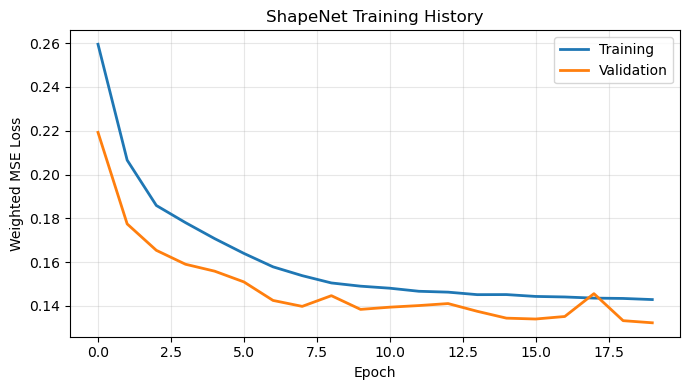

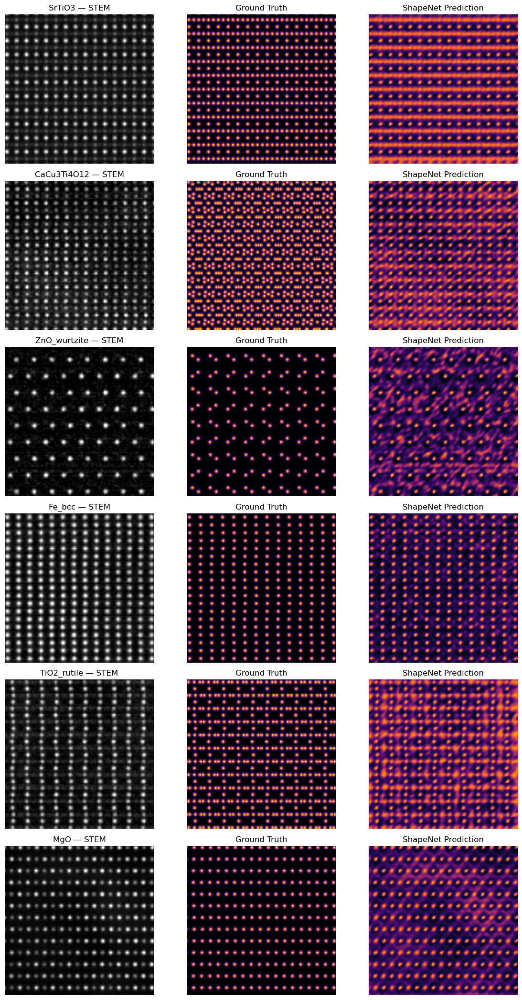

In [62]:
# %% [markdown]
# ## Block 4 — Train ShapeNet on Simulated STEM Data

# %%
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Load multiresolution dataset
# --------------------------------------------------

DATA_DIR = Path.home() / "shapenet_dataset_multires"

for split in ["train", "val"]:
    path = DATA_DIR / f"{split}.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Dataset not found: {path}")


class AtomDataset(Dataset):

    def __init__(self, path):

        with np.load(path) as data:
            self.images = data["images"].astype(np.float32)
            self.heatmaps = data["heatmaps"].astype(np.float32)
            self.structures = data["structures"]
            self.source_sizes = data["source_sizes"]

        assert self.images.shape == self.heatmaps.shape
        assert self.images.shape[1:] == (128, 128)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = torch.from_numpy(
            self.images[idx][None]
        )

        target = torch.from_numpy(
            self.heatmaps[idx][None]
        )

        return image, target


train_dataset = AtomDataset(DATA_DIR / "train.npz")
val_dataset = AtomDataset(DATA_DIR / "val.npz")

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Image size:", train_dataset.images.shape[1:])
print("Device:", device)


# --------------------------------------------------
# 2. Initialize ShapeNet and graph
# --------------------------------------------------

# Start with a fresh model for the new dataset
model = ShapeNetAtomDetector().to(device)

adjacency = tuple(
    tensor.to(device)
    for tensor in build_mesh(size=128)
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters())
)


# --------------------------------------------------
# 3. Atomic-center heatmap loss
# --------------------------------------------------

def heatmap_loss(logits, targets):
    """
    Weighted heatmap regression.

    Higher weight near atomic centers.
    Background pixels are penalized as well.
    """

    predictions = torch.sigmoid(logits)

    weights = 1.0 + 15.0 * targets

    squared_error = (predictions - targets) ** 2

    return (weights * squared_error).mean()


# --------------------------------------------------
# 4. Optimizer and learning-rate scheduler
# --------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

EPOCHS = 20

MODEL_PATH = DATA_DIR / "best_shapenet.pt"

train_losses = []
val_losses = []

best_val = float("inf")


# --------------------------------------------------
# 5. Training and validation
# --------------------------------------------------

for epoch in range(EPOCHS):

    # --------------------------
    # Training
    # --------------------------

    model.train()

    train_loss = 0.0

    for images, targets in train_loader:

        images = images.to(
            device=device,
            dtype=torch.float32
        )

        targets = targets.to(
            device=device,
            dtype=torch.float32
        )

        optimizer.zero_grad()

        logits = model(images, adjacency)

        loss = heatmap_loss(logits, targets)

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_dataset)

    # --------------------------
    # Validation
    # --------------------------

    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for images, targets in val_loader:

            images = images.to(
                device=device,
                dtype=torch.float32
            )

            targets = targets.to(
                device=device,
                dtype=torch.float32
            )

            logits = model(images, adjacency)

            loss = heatmap_loss(logits, targets)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_dataset)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save best validation model
    if val_loss < best_val:

        best_val = val_loss

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f} | "
        f"LR: {current_lr:.2e}"
    )


print("\nTraining completed.")
print("Best validation loss:", best_val)
print("Best model saved to:", MODEL_PATH)


# --------------------------------------------------
# 6. Plot training history
# --------------------------------------------------

plt.figure(figsize=(7, 4))

plt.plot(
    train_losses,
    label="Training",
    linewidth=2
)

plt.plot(
    val_losses,
    label="Validation",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Weighted MSE Loss")
plt.title("ShapeNet Training History")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Load best model
# --------------------------------------------------

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()


# --------------------------------------------------
# 8. Visualize predictions for all six structures
# --------------------------------------------------

structures = list(dict.fromkeys(val_dataset.structures))

fig, axes = plt.subplots(
    len(structures),
    3,
    figsize=(12, 3.5 * len(structures))
)

for row, structure in enumerate(structures):

    # Select a validation patch from a 512x512 simulation
    indices = np.where(
        (val_dataset.structures == structure) &
        (val_dataset.source_sizes == 512)
    )[0]

    i = indices[len(indices) // 2]

    image = val_dataset.images[i]
    target = val_dataset.heatmaps[i]

    tensor = torch.from_numpy(
        image[None, None]
    ).to(device=device, dtype=torch.float32)

    with torch.no_grad():
        prediction = torch.sigmoid(
            model(tensor, adjacency)
        )[0, 0].cpu().numpy()

    # Simulated STEM
    axes[row, 0].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[row, 0].set_title(f"{structure} — STEM")

    # Ground truth
    axes[row, 1].imshow(
        target,
        cmap="inferno",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title("Ground Truth")

    # ShapeNet prediction
    axes[row, 2].imshow(
        prediction,
        cmap="inferno",
        vmin=0,
        vmax=1
    )
    axes[row, 2].set_title("ShapeNet Prediction")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Block 5 — Atom detection and quantitative evaluation

Test images: 378
CaCu3Ti4O12          | P: 0.901 | R: 0.456 | F1: 0.606 | Error: 0.50 px
Fe_bcc               | P: 0.854 | R: 1.000 | F1: 0.921 | Error: 0.39 px
MgO                  | P: 0.884 | R: 0.964 | F1: 0.922 | Error: 0.41 px
SrTiO3               | P: 0.876 | R: 0.605 | F1: 0.715 | Error: 0.47 px
TiO2_rutile          | P: 0.878 | R: 0.648 | F1: 0.746 | Error: 0.53 px
ZnO_wurtzite         | P: 0.785 | R: 0.701 | F1: 0.740 | Error: 0.44 px


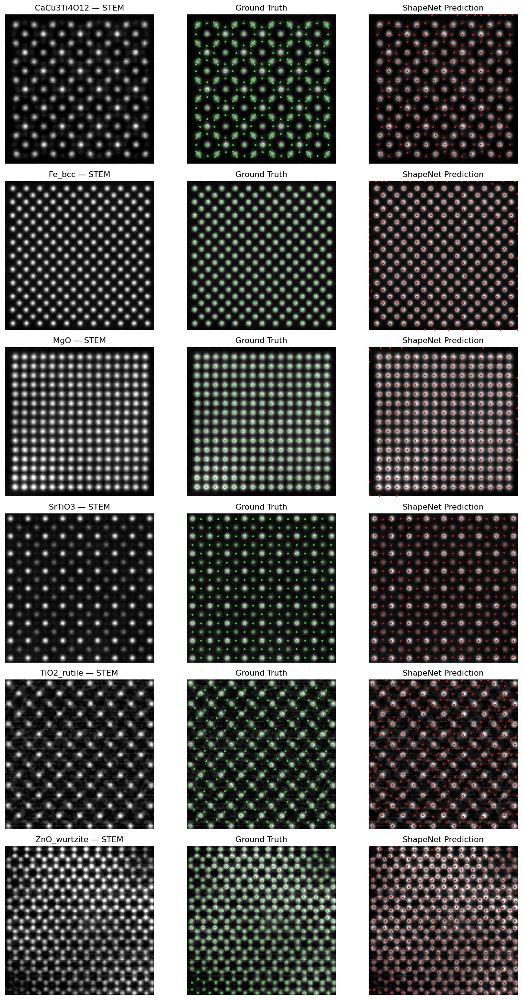

In [64]:
# %%
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree
from scipy.optimize import linear_sum_assignment
from pathlib import Path

DATA_DIR = Path.home() / "shapenet_dataset_multires"

# --------------------------------------------------
# 1. Load trained model and test data
# --------------------------------------------------

model.load_state_dict(
    torch.load(
        DATA_DIR / "best_shapenet.pt",
        map_location=device,
        weights_only=True
    )
)
model.eval()

with np.load(DATA_DIR / "test.npz") as data:
    images = data["images"].astype(np.float32)
    all_coords = data["coords"].astype(np.float32)
    offsets = data["offsets"]
    structures = data["structures"]
    parameters = data["parameters"]

print("Test images:", len(images))


# --------------------------------------------------
# 2. Extract atomic coordinates from heatmaps
# --------------------------------------------------

def detect_atoms(heatmap, threshold=0.3, min_distance=3):
    """
    Detect local maxima in the predicted heatmap.
    Returns atomic coordinates as (x, y).
    """

    local_max = maximum_filter(
        heatmap,
        size=2 * min_distance + 1
    )

    peaks = (
        (heatmap == local_max) &
        (heatmap > threshold)
    )

    y, x = np.where(peaks)

    return np.column_stack([x, y]).astype(np.float32)


# --------------------------------------------------
# 3. Match detected atoms to ground truth
# --------------------------------------------------

def evaluate_atoms(pred_coords, true_coords, tolerance=2.0):
    """
    One-to-one matching with a maximum localization
    tolerance in pixels.
    """

    n_pred = len(pred_coords)
    n_true = len(true_coords)

    if n_pred == 0 or n_true == 0:
        tp = 0
        fp = n_pred
        fn = n_true
        return {
            "precision": 0.0 if n_pred else 1.0,
            "recall": 0.0 if n_true else 1.0,
            "f1": 0.0,
            "error": np.nan,
            "tp": tp,
            "fp": fp,
            "fn": fn
        }

    # Distances between predicted and true centers
    distances = np.linalg.norm(
        pred_coords[:, None, :] - true_coords[None, :, :],
        axis=2
    )

    # Match only within tolerance, prioritizing cardinality
    penalty = tolerance * (max(n_pred, n_true) + 1)
    cost = np.where(distances <= tolerance, distances, penalty)

    rows, cols = linear_sum_assignment(cost)

    matched = distances[rows, cols] <= tolerance

    tp = int(matched.sum())
    fp = n_pred - tp
    fn = n_true - tp

    precision = tp / (tp + fp) if n_pred else 0.0
    recall = tp / (tp + fn) if n_true else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    error = (
        distances[rows[matched], cols[matched]].mean()
        if tp else np.nan
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "error": error,
        "tp": tp,
        "fp": fp,
        "fn": fn
    }


# --------------------------------------------------
# 4. Predict every test image
# --------------------------------------------------

adjacency = tuple(x.to(device) for x in adjacency)

predictions = []

with torch.no_grad():
    for start in range(0, len(images), 4):

        batch = torch.from_numpy(
            images[start:start+4, None]
        ).to(device)

        output = torch.sigmoid(
            model(batch, adjacency)
        )

        predictions.append(
            output[:, 0].cpu().numpy()
        )

predictions = np.concatenate(predictions)


# --------------------------------------------------
# 5. Evaluate each crystal structure
# --------------------------------------------------

results = {}

for structure in np.unique(structures):

    indices = np.where(structures == structure)[0]

    tp_total = fp_total = fn_total = 0
    errors = []

    for i in indices:

        pred_coords = detect_atoms(predictions[i])

        true_coords = all_coords[
            offsets[i]:offsets[i+1]
        ]

        metrics = evaluate_atoms(
            pred_coords,
            true_coords,
            tolerance=2.0
        )

        tp_total += metrics["tp"]
        fp_total += metrics["fp"]
        fn_total += metrics["fn"]

        if metrics["tp"] > 0:
            errors.extend(
                [metrics["error"]] * metrics["tp"]
            )

    precision = tp_total / max(tp_total + fp_total, 1)
    recall = tp_total / max(tp_total + fn_total, 1)
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results[structure] = (precision, recall, f1)

    print(
        f"{structure:20s} | "
        f"P: {precision:.3f} | "
        f"R: {recall:.3f} | "
        f"F1: {f1:.3f} | "
        f"Error: {np.mean(errors) if errors else np.nan:.2f} px"
    )


# --------------------------------------------------
# 6. Visualize predictions for all six structures
# --------------------------------------------------

unique_structures = list(np.unique(structures))

fig, axes = plt.subplots(
    len(unique_structures), 3,
    figsize=(12, 3.5 * len(unique_structures))
)

for row, structure in enumerate(unique_structures):

    i = np.where(structures == structure)[0][0]

    image = images[i]
    pred = predictions[i]

    true_coords = all_coords[
        offsets[i]:offsets[i+1]
    ]
    pred_coords = detect_atoms(pred)

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"{structure} — STEM")

    axes[row, 1].imshow(image, cmap="gray")
    axes[row, 1].scatter(
        true_coords[:, 0], true_coords[:, 1],
        s=12, c="lime", marker="+"
    )
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].scatter(
        pred_coords[:, 0], pred_coords[:, 1],
        s=12, c="red", marker="+"
    )
    axes[row, 2].set_title("ShapeNet Prediction")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Block 6 — Test ShapeNet on experimental YBCO

YBCO               | Image: (128, 128) | Detected columns: 160
Silicon (SiSb)     | Image: (128, 128) | Detected columns: 139


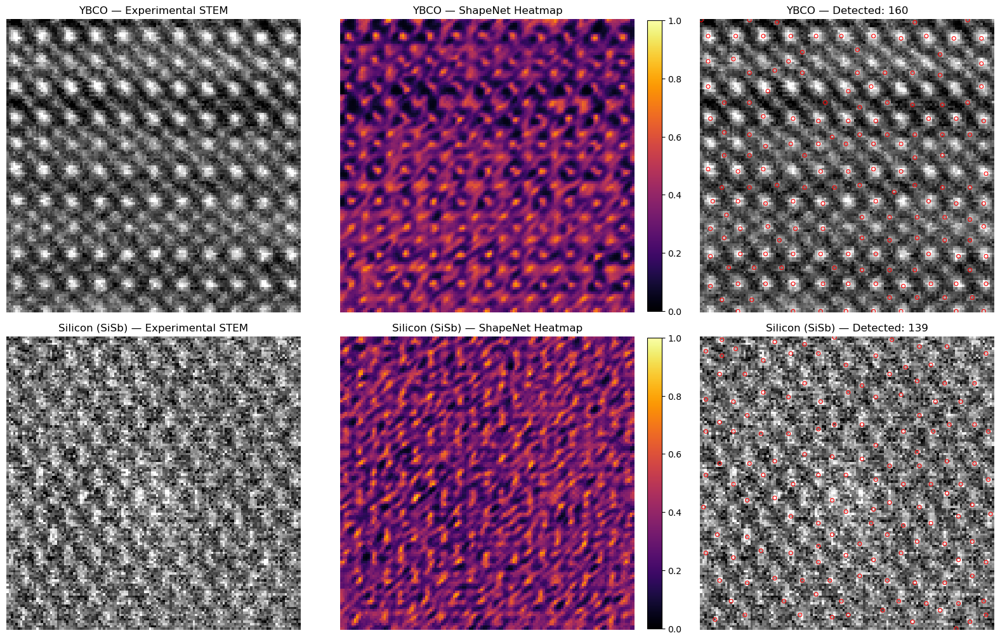

In [84]:

# %% [markdown]
# ## Block 6 — ShapeNet on Experimental YBCO and Silicon

# %%
import numpy as np
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from scipy.ndimage import maximum_filter

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PREDICTION_SIZE = 128     # 128, 256, 512, or "full"

YBCO_INDEX = 0
SILICON_INDEX = 1

TILE_SIZE = 16
OVERLAP = 5

THRESHOLD = 0.6
MIN_DISTANCE = 5

DATA_DIR = Path.home() / "shapenet_dataset_multires"

# --------------------------------------------------
# 2. Load trained ShapeNet
# --------------------------------------------------

model.load_state_dict(
    torch.load(
        DATA_DIR / "best_shapenet.pt",
        map_location=device,
        weights_only=True
    )
)

model = model.to(device)
model.eval()

adjacency = tuple(
    tensor.to(device)
    for tensor in build_mesh(TILE_SIZE)
)

# --------------------------------------------------
# 3. Prepare experimental image
# --------------------------------------------------

def prepare_image(image, prediction_size):

    original = np.asarray(image, dtype=np.float32)

    if original.ndim != 2:
        raise ValueError("Expected a 2D STEM image")

    H, W = original.shape

    if prediction_size == "full":

        cropped = original.copy()
        x0, y0 = 0, 0

    elif prediction_size in [128, 256, 512]:

        S = prediction_size

        if H < S or W < S:
            raise ValueError(
                f"Requested {S}x{S}, "
                f"but image size is {H}x{W}"
            )

        y0 = (H - S) // 2
        x0 = (W - S) // 2

        cropped = original[
            y0:y0+S,
            x0:x0+S
        ].copy()

    else:
        raise ValueError(
            "PREDICTION_SIZE must be "
            "128, 256, 512, or 'full'"
        )

    # Robust intensity normalization
    p1, p99 = np.percentile(cropped, [1, 99])

    cropped = np.clip(
        (cropped - p1) / (p99 - p1 + 1e-8),
        0, 1
    ).astype(np.float32)

    return cropped, (x0, y0)


# --------------------------------------------------
# 4. Full-resolution tiled inference
# --------------------------------------------------

def predict_full_image(
    model,
    image,
    adjacency,
    device,
    tile_size=128,
    overlap=32
):

    H, W = image.shape
    stride = tile_size - overlap

    if stride <= 0:
        raise ValueError(
            "Overlap must be smaller than tile size"
        )

    # Pad only if image is smaller than one tile
    pad_h = max(0, tile_size - H)
    pad_w = max(0, tile_size - W)

    padded = np.pad(
        image,
        ((0, pad_h), (0, pad_w)),
        mode="reflect"
    )

    PH, PW = padded.shape

    prediction = np.zeros(
        (PH, PW), dtype=np.float32
    )

    weights = np.zeros_like(prediction)

    # Generate tile positions
    ys = list(range(
        0, PH - tile_size + 1, stride
    ))

    xs = list(range(
        0, PW - tile_size + 1, stride
    ))

    if ys[-1] != PH - tile_size:
        ys.append(PH - tile_size)

    if xs[-1] != PW - tile_size:
        xs.append(PW - tile_size)

    # Smooth blending window
    window = np.outer(
        np.hanning(tile_size),
        np.hanning(tile_size)
    ).astype(np.float32)

    window = np.maximum(window, 0.05)

    model.eval()

    with torch.no_grad():

        for y in ys:
            for x in xs:

                patch = padded[
                    y:y+tile_size,
                    x:x+tile_size
                ]

                tensor = torch.from_numpy(
                    patch[None, None].copy()
                ).to(
                    device=device,
                    dtype=torch.float32
                )

                output = torch.sigmoid(
                    model(tensor, adjacency)
                )[0, 0].cpu().numpy()

                prediction[
                    y:y+tile_size,
                    x:x+tile_size
                ] += output * window

                weights[
                    y:y+tile_size,
                    x:x+tile_size
                ] += window

    prediction /= np.maximum(
        weights, 1e-8
    )

    return prediction[:H, :W]


# --------------------------------------------------
# 5. Detect atomic columns
# --------------------------------------------------

def detect_atoms(
    heatmap,
    threshold=0.6,
    min_distance=7
):
    """
    Detect local maxima in the ShapeNet heatmap.

    Returns:
        coordinates: [N, 2] in (x, y) order
    """

    local_max = maximum_filter(
        heatmap,
        size=2 * min_distance + 1
    )

    peaks = (
        (heatmap == local_max) &
        (heatmap > threshold)
    )

    y, x = np.where(peaks)

    return np.column_stack(
        [x, y]
    ).astype(np.float32)


# --------------------------------------------------
# 6. Run ShapeNet on YBCO and Silicon
# --------------------------------------------------

EXPERIMENTAL_DATASETS = {
    "YBCO": ybco_images[YBCO_INDEX],
    "Silicon (SiSb)": sisb_images[SILICON_INDEX]
}

results = {}

for name, original_image in EXPERIMENTAL_DATASETS.items():

    # Select prediction region
    image, origin = prepare_image(
        original_image,
        PREDICTION_SIZE
    )

    # Predict atomic-center heatmap
    prediction = predict_full_image(
        model=model,
        image=image,
        adjacency=adjacency,
        device=device,
        tile_size=TILE_SIZE,
        overlap=OVERLAP
    )

    # Extract coordinates
    coords = detect_atoms(
        prediction,
        threshold=THRESHOLD,
        min_distance=MIN_DISTANCE
    )

    # Coordinates in original experimental image
    coords_original = coords.copy()

    coords_original[:, 0] += origin[0]
    coords_original[:, 1] += origin[1]

    results[name] = {
        "image": image,
        "heatmap": prediction,
        "coords": coords,
        "coords_original": coords_original,
        "origin": origin
    }

    print(
        f"{name:18s} | "
        f"Image: {image.shape} | "
        f"Detected columns: {len(coords)}"
    )


# --------------------------------------------------
# 7. Visualize both experimental datasets
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

for row, (name, result) in enumerate(results.items()):

    image = result["image"]
    heatmap = result["heatmap"]
    coords = result["coords"]

    # Column 1: Experimental STEM
    axes[row, 0].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row, 0].set_title(
        f"{name} — Experimental STEM"
    )

    # Column 2: ShapeNet heatmap
    im = axes[row, 1].imshow(
        heatmap,
        cmap="inferno",
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title(
        f"{name} — ShapeNet Heatmap"
    )

    # Column 3: Detected atomic columns
    axes[row, 2].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row, 2].scatter(
        coords[:, 0],
        coords[:, 1],
        s=18,
        facecolors="none",
        edgecolors="red",
        linewidths=0.8
    )

    axes[row, 2].set_title(
        f"{name} — Detected: {len(coords)}"
    )

    for ax in axes[row]:
        ax.axis("off")

    fig.colorbar(
        im,
        ax=axes[row, 1],
        fraction=0.046,
        pad=0.04
    )

plt.show()
